# Tarea 2 · Parte 2 — De los modelos base a la extracción estructurada

**Fecha de evaluación:** 25 de octubre de 2026 · **Estudiante:** @fampueroc · todo en CPU local, sin APIs de pago.

### Diseño de la evaluación (fijado antes de mirar ninguna métrica)

| | Documentos | Audio |
|---|---|---|
| **Muestra** | 10 de los 25 documentos de la Parte 1: 3 impresos, 4 fotos, 3 manuscritos | 10 de los 29 clips: 5 entrevistas reales de Commons + 5 frases leídas de OpenSLR 73 |
| **Referencia** | transcripción manual de la estudiante (`datos/referencias/`) | manual de la estudiante (entrevistas) y transcripción humana oficial de OpenSLR 73 (lecturas) |
| **Línea base** | PaddleOCR 3.7 sin personalización (PP-OCRv6) | faster-whisper `small`, CPU int8, VAD on |
| **Modelos comparados** | Tesseract 5.4 (`spa`, LSTM) | faster-whisper `large-v3-turbo` (el de la Parte 1) y Meta MMS-1b-all (`spa`) |
| **Métrica** | CER | WER (+ factor de tiempo real) |

Reglas: mismos 10 archivos para todos los modelos; ningún parámetro se ajustó mirando estos resultados; referencia e hipótesis se
normalizan igual (minúsculas, sin puntuación, sin marcas `[HABLANTE_n]`, mismos seudónimos).

In [1]:
import json
import os
import re
import sys
import time
import warnings
from pathlib import Path

os.environ["PADDLE_PDX_DISABLE_MODEL_SOURCE_CHECK"] = "True"
os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore")

import jiwer
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio

RAIZ = Path.cwd()
sys.path.insert(0, str(RAIZ.parent / "sessions" / "13-audio-a-texto"))
import voz
from voz import SR, cargar_audio

DATOS, RAW = RAIZ / "datos", RAIZ / "datos" / "raw"
DIR_EVAL = RAW / "evaluacion"
DIR_EVAL.mkdir(parents=True, exist_ok=True)
pio.renderers.default = "notebook_connected+png"
pd.set_option("display.max_colwidth", 80)

documentos = pd.read_csv(DATOS / "documentos.csv", keep_default_na=False)
transcripciones = pd.read_csv(DATOS / "transcripciones.csv", keep_default_na=False)
print(documentos.shape, transcripciones.shape)

(25, 7) (29, 8)


## 1 · Muestra de evaluación y referencias manuales

In [2]:
EVAL_DOCS = ["doc_002", "doc_003", "doc_007", "doc_009", "doc_010", "doc_011", "doc_015", "doc_018", "doc_019", "doc_020"]
EVAL_ENTREVISTAS = ["clip_006", "clip_007", "clip_010", "clip_016", "clip_017"]
EVAL_LECTURAS = ["clip_020", "clip_022", "clip_024", "clip_026", "clip_028"]
EVAL_CLIPS = EVAL_ENTREVISTAS + EVAL_LECTURAS

# seudónimos: el mismo diccionario privado de la Parte 1 se aplica a referencias e hipótesis
_s = json.loads((RAW / "seudonimos.json").read_text(encoding="utf-8")) if (RAW / "seudonimos.json").exists() else {}
SEUD = {"documento": _s.get("documentos", {}), "audio": _s.get("audio", {})}


def seudonimizar(texto, modalidad):
    texto = voz.seudonimizar(texto, SEUD[modalidad], parecido=85)
    return re.sub(r"\b9\d{8}\b", "[TELEFONO]", re.sub(r"\b\d{8}\b", "[DNI]", texto))


oficial = pd.read_csv(RAW / "audio" / "openslr73.csv").set_index("id")["transcripcion_oficial"]
refs = {}
for id_ in EVAL_DOCS + EVAL_ENTREVISTAS:
    texto = (DATOS / "referencias" / f"{id_}.txt").read_text(encoding="utf-8").strip()
    assert texto, f"Falta la referencia manual de {id_}"
    refs[id_] = seudonimizar(texto, "documento" if id_.startswith("doc") else "audio")
for id_ in EVAL_LECTURAS:
    refs[id_] = oficial[id_]

documentos["texto_referencia"] = documentos["id"].map(refs).fillna("")
transcripciones["texto_referencia"] = transcripciones["id"].map(refs).fillna("")
documentos.to_csv(DATOS / "documentos.csv", index=False)
transcripciones.to_csv(DATOS / "transcripciones.csv", index=False)

ev_docs = documentos[documentos["id"].isin(EVAL_DOCS)].set_index("id").loc[EVAL_DOCS]
ev_clips = transcripciones[transcripciones["id"].isin(EVAL_CLIPS)].set_index("id").loc[EVAL_CLIPS]
print("Documentos:", ev_docs["tipo"].value_counts().to_dict())
print(f"Clips: {len(ev_clips)} · {ev_clips['duracion_seg'].sum() / 60:.1f} min de audio")
pd.DataFrame({"id": list(refs), "referencia (inicio)": [r[:80] for r in refs.values()]})

Documentos: {'foto': 4, 'impreso': 3, 'manuscrito': 3}
Clips: 10 · 4.7 min de audio


,id,referencia (inicio)
0,doc_002,BANCO CENTRAL DE RESERVA DEL PERÚ\n500000\nQUINIENTOS MIL INTIS\n21 DE DICIE...
1,doc_003,BANCO CENTRAL DE RESERVA DEL PERÚ\nB\n6\n0\n7\n5\n0\n2\n9\nN\nMIL INTIS\n28 ...
2,doc_007,CONSTITUCIÓN POLÍTICA [ilegible] PERUANA\n\nLima 1823
3,doc_009,BARRIO CHINO\nCALLE CAPON
4,doc_010,ENTRADAS\nGnocchi\nCeviche de pato\nJamón c/ espárragos\nTiradito de pato\nC...
5,doc_011,PICANTE DE CUY
6,doc_015,[ilegible]\n\nSu Santidad Juan Pablo II\nPastor Universal Obispo De Roma\nY ...
7,doc_018,[ilegible]\nAgradezco muy sinceramente\nla fina atención de mi joven a-\nmig...
8,doc_019,Nº 8219\n\nTeléfono No. [ilegible]\n\nPERUVIAN TELEPHONE COMPANY.\n\nContrat...
9,doc_020,N° 2111\n\nJuan\n[ilegible]\nPorras.\n\n[ilegible] Juan Clemente de [ilegibl...


### Normalización común

`voz.normalizar` (Sesión 13): minúsculas y sin puntuación, conservando tildes. Antes se quitan las marcas de hablante
(`[HABLANTE_1]`, que no son palabras habladas) y `[ilegible]` (en la referencia no sabemos qué dice). Los seudónimos (`[PERSONA_1]`)
se conservan como una palabra más, idénticos en referencia e hipótesis.

In [3]:
def limpiar(texto):
    texto = re.sub(r"\[(HABLANTE_\d+|ilegible)\]", " ", str(texto), flags=re.I)
    return voz.normalizar(texto)


def cer(ref, hip):
    return jiwer.cer(limpiar(ref), limpiar(hip) or "∅")


def wer(ref, hip):
    return jiwer.wer(limpiar(ref), limpiar(hip) or "∅")


def cer_corpus(refs, hips):
    "CER agregado: errores totales / caracteres totales de la referencia (no promedio de tasas)."
    return jiwer.cer([limpiar(r) for r in refs], [limpiar(h) or "∅" for h in hips])


def wer_corpus(refs, hips):
    return jiwer.wer([limpiar(r) for r in refs], [limpiar(h) or "∅" for h in hips])

## 2 · Línea base sin ajuste

**Documentos — PaddleOCR 3.7 base:** es exactamente la salida de la Parte 1 (`texto_ocr`), sin tocar nada.
La latencia se lee del respaldo crudo de cada documento.

In [4]:
seg_ocr = {i: json.loads((RAW / "documentos" / "ocr" / f"{i}.json").read_text(encoding="utf-8"))["segundos"] for i in EVAL_DOCS}
res_docs = pd.DataFrame({"id": EVAL_DOCS, "tipo": ev_docs["tipo"].values,
                         "cer_paddle": [cer(ev_docs.loc[i, "texto_referencia"], ev_docs.loc[i, "texto_ocr"]) for i in EVAL_DOCS],
                         "seg_paddle": [seg_ocr[i] for i in EVAL_DOCS]})
CER_PADDLE = cer_corpus(ev_docs["texto_referencia"], ev_docs["texto_ocr"])
print(f"CER línea base PaddleOCR (10 documentos): {CER_PADDLE:.3f}")
res_docs.round(3)

CER línea base PaddleOCR (10 documentos): 0.580


,id,tipo,cer_paddle,seg_paddle
0,doc_002,impreso,0.388,29.302
1,doc_003,impreso,0.470,26.407
2,doc_007,impreso,0.487,16.070
3,doc_009,foto,1.333,94.017
4,doc_010,foto,0.737,68.930
5,doc_011,foto,1.000,51.585
6,doc_015,foto,0.046,75.548
7,doc_018,manuscrito,0.274,97.002
8,doc_019,manuscrito,0.532,38.381
9,doc_020,manuscrito,2.090,41.889


**Audio — faster-whisper `small` en CPU:** configuración base pedida por el enunciado (`int8`, `beam_size=5`, `language="es"`,
VAD on). Se cronometra solo la transcripción (sin la carga del modelo) para calcular el **factor de tiempo real**
(RTF = segundos de cómputo / segundos de audio).

In [5]:
from faster_whisper import WhisperModel

audios = {i: cargar_audio(RAIZ / ev_clips.loc[i, "archivo_audio"]) for i in EVAL_CLIPS}


def correr_asr(nombre, transcribir):
    "Corre un ASR sobre los 10 clips con caché en disco; devuelve texto y segundos de cómputo por clip."
    cache = DIR_EVAL / f"asr_{nombre}.json"
    if cache.exists():
        return json.loads(cache.read_text(encoding="utf-8"))
    salida = {}
    for i, x in audios.items():
        t0 = time.perf_counter()
        texto = transcribir(x)
        salida[i] = {"texto": seudonimizar(texto, "audio"), "segundos": time.perf_counter() - t0}
    cache.write_text(json.dumps(salida, ensure_ascii=False), encoding="utf-8")
    return salida


def con_whisper(repo):
    modelo = WhisperModel(repo, device="cpu", compute_type="int8", cpu_threads=16)
    return lambda x: " ".join(s.text.strip() for s in modelo.transcribe(x, language="es", beam_size=5, vad_filter=True)[0])


asr = {"whisper_small": correr_asr("whisper_small", con_whisper("Systran/faster-whisper-small"))}


def tabla_asr(nombre):
    r = asr[nombre]
    return pd.DataFrame({"id": EVAL_CLIPS, f"wer_{nombre}": [wer(refs[i], r[i]["texto"]) for i in EVAL_CLIPS],
                         f"rtf_{nombre}": [r[i]["segundos"] / ev_clips.loc[i, "duracion_seg"] for i in EVAL_CLIPS]})


res_clips = pd.DataFrame({"id": EVAL_CLIPS, "fuente": ["entrevista"] * 5 + ["lectura"] * 5,
                          "duracion_seg": ev_clips["duracion_seg"].values}).merge(tabla_asr("whisper_small"), on="id")
WER_SMALL = wer_corpus([refs[i] for i in EVAL_CLIPS], [asr["whisper_small"][i]["texto"] for i in EVAL_CLIPS])
print(f"WER línea base faster-whisper small (10 clips): {WER_SMALL:.3f}")
res_clips.round(3)

WER línea base faster-whisper small (10 clips): 0.218


,id,fuente,duracion_seg,wer_whisper_small,rtf_whisper_small
0,clip_006,entrevista,29.9,0.490,0.177
1,clip_007,entrevista,54.3,0.324,0.296
2,clip_010,entrevista,77.4,0.271,0.212
3,clip_016,entrevista,43.8,0.101,0.225
4,clip_017,entrevista,44.0,0.096,0.193
5,clip_020,lectura,7.0,0.067,0.300
6,clip_022,lectura,7.5,0.000,0.273
7,clip_024,lectura,5.2,0.077,0.381
8,clip_026,lectura,5.5,0.100,0.363
9,clip_028,lectura,7.8,0.050,0.275


## 3 · Comparación de modelos sobre las mismas muestras

### 3.1 Documentos: PaddleOCR frente a Tesseract

Tesseract 5.4 (motor LSTM, paquete de idioma `spa` de *tessdata_fast*, `--psm 3` = segmentación automática de página) es el OCR
abierto clásico que sugiere el enunciado. Mismo archivo de imagen, mismo criterio de normalización.

In [6]:
import pytesseract
from PIL import Image

pytesseract.pytesseract.tesseract_cmd = r"C:\Program Files\Tesseract-OCR\tesseract.exe"
os.environ["TESSDATA_PREFIX"] = str(RAIZ / "modelos" / "tessdata")    # spa.traineddata de tessdata_fast
print("Tesseract", pytesseract.get_tesseract_version())


def tesseract(ruta):
    return pytesseract.image_to_string(Image.open(ruta), lang="spa", config="--psm 3")


cache = DIR_EVAL / "ocr_tesseract.json"
if cache.exists():
    tess = json.loads(cache.read_text(encoding="utf-8"))
else:
    tess = {}
    for i in EVAL_DOCS:
        t0 = time.perf_counter()
        texto = tesseract(RAIZ / ev_docs.loc[i, "archivo"])
        tess[i] = {"texto": seudonimizar(" ".join(texto.split()), "documento"), "segundos": time.perf_counter() - t0}
    cache.write_text(json.dumps(tess, ensure_ascii=False), encoding="utf-8")

res_docs["cer_tesseract"] = [cer(ev_docs.loc[i, "texto_referencia"], tess[i]["texto"]) for i in EVAL_DOCS]
res_docs["seg_tesseract"] = [tess[i]["segundos"] for i in EVAL_DOCS]
CER_TESS = cer_corpus(ev_docs["texto_referencia"], [tess[i]["texto"] for i in EVAL_DOCS])
print(f"CER PaddleOCR: {CER_PADDLE:.3f} · CER Tesseract: {CER_TESS:.3f}")
res_docs.round(3)

Tesseract 5.4.0.20240606
CER PaddleOCR: 0.580 · CER Tesseract: 0.688


,id,tipo,cer_paddle,seg_paddle,cer_tesseract,seg_tesseract
0,doc_002,impreso,0.388,29.302,0.934,0.387
1,doc_003,impreso,0.470,26.407,0.732,0.307
2,doc_007,impreso,0.487,16.070,0.769,0.142
3,doc_009,foto,1.333,94.017,1.000,0.313
4,doc_010,foto,0.737,68.930,0.741,0.715
5,doc_011,foto,1.000,51.585,1.000,0.212
6,doc_015,foto,0.046,75.548,0.354,0.524
7,doc_018,manuscrito,0.274,97.002,0.462,1.045
8,doc_019,manuscrito,0.532,38.381,0.617,0.335
9,doc_020,manuscrito,2.090,41.889,1.540,0.374


### 3.2 Audio: faster-whisper `small` vs `large-v3-turbo` vs Meta MMS

- **faster-whisper `large-v3-turbo`:** el modelo usado en la Parte 1 (misma configuración, ahora cronometrado en la muestra).
- **Meta MMS-1b-all con adaptador `spa`:** el ASR multilingüe de Meta (CTC, sin puntuación) corriendo sobre los tramos de voz del
  VAD con `voz.Transcriptor`, como en la Sesión 13.

In [7]:
asr["whisper_turbo"] = correr_asr("whisper_turbo", con_whisper("mobiuslabsgmbh/faster-whisper-large-v3-turbo"))


def con_mms(idioma):
    t = voz.Transcriptor("mms", device="cpu", idioma_mms=idioma)
    return lambda x: " ".join(s.texto for s in t.segmentos(x))


asr["mms_spa"] = correr_asr("mms_spa", con_mms("spa"))

for nombre in ["whisper_turbo", "mms_spa"]:
    res_clips = res_clips.merge(tabla_asr(nombre), on="id")
WER = {n: wer_corpus([refs[i] for i in EVAL_CLIPS], [asr[n][i]["texto"] for i in EVAL_CLIPS]) for n in asr}
RTF = {n: sum(asr[n][i]["segundos"] for i in EVAL_CLIPS) / ev_clips["duracion_seg"].sum() for n in asr}
print(pd.DataFrame({"WER": WER, "RTF": RTF}).round(3))
res_clips.round(3)

                 WER    RTF
whisper_small  0.218  0.235
whisper_turbo  0.208  0.501
mms_spa        0.313  0.387


,id,fuente,duracion_seg,wer_whisper_small,rtf_whisper_small,wer_whisper_turbo,rtf_whisper_turbo,wer_mms_spa,rtf_mms_spa
0,clip_006,entrevista,29.9,0.490,0.177,0.588,0.503,0.882,0.430
1,clip_007,entrevista,54.3,0.324,0.296,0.317,0.506,0.403,0.401
2,clip_010,entrevista,77.4,0.271,0.212,0.239,0.367,0.400,0.372
3,clip_016,entrevista,43.8,0.101,0.225,0.059,0.408,0.143,0.415
4,clip_017,entrevista,44.0,0.096,0.193,0.096,0.380,0.117,0.428
5,clip_020,lectura,7.0,0.067,0.300,0.067,1.028,0.067,0.283
6,clip_022,lectura,7.5,0.000,0.273,0.000,0.965,0.000,0.321
7,clip_024,lectura,5.2,0.077,0.381,0.077,1.386,0.077,0.270
8,clip_026,lectura,5.5,0.100,0.363,0.100,1.312,0.300,0.209
9,clip_028,lectura,7.8,0.050,0.275,0.050,0.926,0.050,0.241


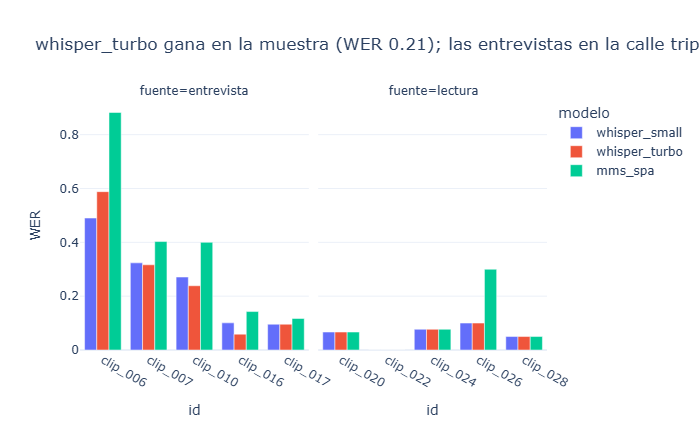

modelo,mms_spa,whisper_small,whisper_turbo
fuente,,,
entrevista,0.389,0.256,0.260
lectura,0.099,0.059,0.059


In [8]:
largo = res_clips.melt(id_vars=["id", "fuente"], value_vars=[f"wer_{n}" for n in asr], var_name="modelo", value_name="WER")
largo["modelo"] = largo["modelo"].str.removeprefix("wer_")
por_fuente = largo.groupby(["fuente", "modelo"])["WER"].mean().unstack()
mejor = min(WER, key=WER.get)
fig = px.bar(largo, x="id", y="WER", color="modelo", barmode="group", facet_col="fuente",
             category_orders={"fuente": ["entrevista", "lectura"]},
             title=(f"{mejor} gana en la muestra (WER {WER[mejor]:.2f}); las entrevistas en la calle triplican o más "
                    f"el error de las lecturas"))
fig.update_xaxes(matches=None)
fig.update_layout(template="plotly_white", height=430)
fig.show()
por_fuente.round(3)

## 4 · Casos difíciles

### 4.1 Documentos por tipo

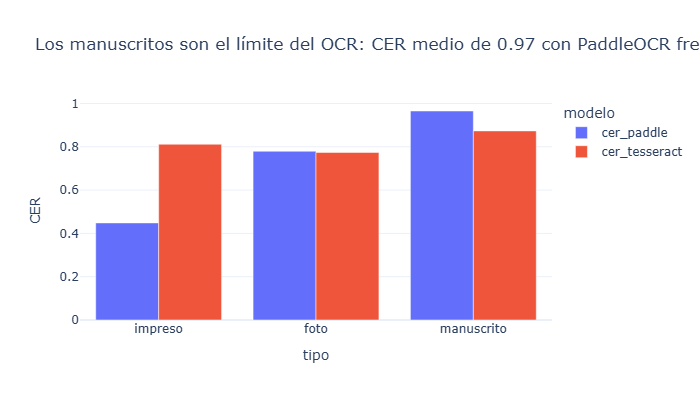

,cer_paddle,cer_tesseract
tipo,,
impreso,0.448,0.812
foto,0.779,0.774
manuscrito,0.965,0.873


In [9]:
por_tipo = res_docs.groupby("tipo")[["cer_paddle", "cer_tesseract"]].mean().reindex(["impreso", "foto", "manuscrito"])
fig = px.bar(por_tipo.reset_index().melt(id_vars="tipo", var_name="modelo", value_name="CER"), x="tipo", y="CER",
             color="modelo", barmode="group",
             title=(f"Los manuscritos son el límite del OCR: CER medio de {por_tipo.loc['manuscrito', 'cer_paddle']:.2f} "
                    f"con PaddleOCR frente a {por_tipo.loc['impreso', 'cer_paddle']:.2f} en impresos"))
fig.update_layout(template="plotly_white", height=400)
fig.show()
por_tipo.round(3)

In [10]:
# ¿Qué falla en un manuscrito? Referencia frente a las dos lecturas automáticas
for i in ["doc_018", "doc_019"]:
    print(f"── {i} ({ev_docs.loc[i, 'tipo']}) ──")
    print("REFERENCIA :", ev_docs.loc[i, "texto_referencia"][:300])
    print("PADDLEOCR  :", ev_docs.loc[i, "texto_ocr"][:300])
    print("TESSERACT  :", tess[i]["texto"][:300], "\n")

── doc_018 (manuscrito) ──
REFERENCIA : [ilegible]
Agradezco muy sinceramente
la fina atención de mi joven a-
migo Luis Antonio Eguiguren al
obsequiarme los dos folletitos cuya lec-
tura haré próximamente, y le estimaré
infinito que, cuando sea posible, favo-
rezca con su ofrecida visita a éste
su valetudinario amigo  

Ricardo Palma
Mira
PADDLEOCR  : Agradenco muy sineeromenls  ming, mio Untomin Eginiguren al infimits gut, rnmanth b and pooitle, Gavo- roxia con in oprcita slite aest Merafhores, 2hode Oetibre de/912. Tarjeta dirigida a Luis Antonio Eguiguren por Don Ricardo Palma: "Agradezco muy sinceramente la fina atención de mi joven amigo Lui
TESSERACT  : Tarjeta dirigida a Luis Antonio Eguiguren por Don Ricardo Palma: "Agradezco muy sinceramente la fina atención de mi joven amigo Luis Antonio Eguiguren al obsequiarme dos folleti tos cuya lectura haré próximamente, y le estimaré infinito que, cuando sea posible, favorezca con su ofrecida visita a ést 

── doc_019 (manuscrito) ──
RE

### 4.2 Audio con ruido o música

In [11]:
# clip_006: mini entrevistas en el estadio (ruido de multitud) · clip_005: megáfono con música religiosa de fondo (fuera de la muestra)
for i in ["clip_006"]:
    print(f"── {i} · WER small {res_clips.set_index('id').loc[i, 'wer_whisper_small']:.2f} · "
          f"turbo {res_clips.set_index('id').loc[i, 'wer_whisper_turbo']:.2f} · MMS {res_clips.set_index('id').loc[i, 'wer_mms_spa']:.2f}")
    print("REFERENCIA:", refs[i][:400])
    for n in asr:
        print(f"{n:14}:", asr[n][i]["texto"][:400])
seg5 = json.loads((RAW / "audio" / "salidas" / "clip_005.json").read_text(encoding="utf-8"))
print(f"\nclip_005 (música + megáfono): {seg5['segundos_voz']:.0f} s de voz según el VAD de {seg5['duracion_seg']:.0f} s; "
      f"primeros segmentos de Whisper:")
for s in seg5["segmentos"][:6]:
    print(f"  [{s['inicio']:6.1f}-{s['fin']:6.1f}] {s['hablante']}: {seudonimizar(s['texto'], 'audio')[:100]}")

── clip_006 · WER small 0.49 · turbo 0.59 · MMS 0.88
REFERENCIA: normal pues te dan los resultados
pero como lo ves, como ves a peru?
no se entiende pe, hay como 4 jugadores que estan por las puras, ahora el tecnico tiene que hacer los cambios pe no, supongo que esos 4 jugadores
carrillo canchita trauco y ala el otro si aaa
whisper_small : normal es pedando resultados pero como lo ves? como ves a perú ahorita? como ves a perú? no se entiende no se están entendiendo hay como 4 jugadores que están por las puras y ahora el técnico tiene que ser justo los cambios supongo esos 4 jugadores Carrillo, Canchita Trauco y ahora el otro sino
whisper_turbo : normal esperando el resultado pero como lo ves como ves a perú ahorita que está no se entiende no se están entendiendo no no hay como cuatro jugadores que están por las puras y ahora el técnico tiene que hacer justo los cambios supongo esos cuatro jugadores carrillo canchita este trauco y y a la lucha
mms_spa       : normal preferendo presentar

### 4.3 Bonificación: quechua de Huaylas con MMS

Para `clip_018` (Shansha, Áncash) no existe una transcripción humana publicada y la estudiante no habla quechua de Huaylas, así
que **no se reporta un WER** (inventar una referencia sería un dato falso). Se compara cualitativamente Whisper (que no tiene
quechua) con MMS `qwh` sobre los mismos 30 s.

In [12]:
xq = cargar_audio(RAIZ / transcripciones.set_index("id").loc["clip_018", "archivo_audio"])[:30 * SR]
cache = DIR_EVAL / "quechua_clip018.json"
if cache.exists():
    q = json.loads(cache.read_text(encoding="utf-8"))
else:
    w = WhisperModel("mobiuslabsgmbh/faster-whisper-large-v3-turbo", device="cpu", compute_type="int8", cpu_threads=16)
    segs, info = w.transcribe(xq, beam_size=5, vad_filter=True)
    q = {"whisper": " ".join(s.text.strip() for s in segs), "idioma_whisper": info.language,
         "mms_qwh": voz.Transcriptor("mms", device="cpu", idioma_mms="qwh").transcribir(xq)}
    cache.write_text(json.dumps(q, ensure_ascii=False), encoding="utf-8")
print(f"Whisper (detecta '{q['idioma_whisper']}'):", seudonimizar(q["whisper"], "audio"))
print("\nMMS [qwh]:", seudonimizar(q["mms_qwh"], "audio"))

Whisper (detecta 'es'): ¿Cómo se llama? [PERSONA_15] ¿Cómo se llama? ¿Cómo se llama? ¿Cómo se llama? ¿Cómo se llama? ¿Que se llama? ¿Qué tipo de enfermedad? ¿Cómo se llama? ¿Qué tipo de enfermedad?

MMS [qwh]: mataqtiqi juti [PERSONA_15] tapurishqequi que planta medisinacunapaqa r y imataq juticun que planta y lanta juticun auinsham imapaq sirbin que qora que awrinsha sirbin inframasion labani


## 5 · Extracción estructurada con LLM local y auditoría humana

**Modelo:** `Qwen/Qwen2.5-1.5B-Instruct` (Apache 2.0) con `transformers` en CPU, decodificación determinista (`do_sample=False`),
sin API ni costo. Se procesan los **54 registros** (25 documentos + 29 clips) usando el texto ya seudonimizado.

Prompt estructurado: el modelo debe devolver **solo JSON** con `modalidad`, `tema`, `resumen` y, en documentos, `emisor`, `fecha` y
`monto` **solo si aparecen en el texto**; en audios, `numero_hablantes` (de la diarización) y `citas_clave` textuales. Lo
ausente va como `null`. Después del modelo, una **verificación automática anti-invención** anula `fecha`/`monto`/`citas_clave`
que no aparecen literalmente en el texto fuente, y se registra cuántos se anularon.

In [13]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

MODELO_LLM = "Qwen/Qwen2.5-1.5B-Instruct"
DIR_LLM = RAW / "llm"
DIR_LLM.mkdir(exist_ok=True)
torch.set_num_threads(16)

SISTEMA = ("Eres un archivista que extrae metadatos de textos peruanos obtenidos por OCR o por transcripción de audio. "
           "Responde SOLO con un objeto JSON válido, sin texto adicional. No inventes: si un dato no aparece en el texto, usa null.")
CAMPOS = {
    "documento": '{"modalidad": "documento", "tema": "<2 a 5 palabras>", "resumen": "<una oración>", '
                 '"emisor": "<institución o persona que emite el documento, o null>", '
                 '"fecha": "<fecha tal como aparece en el texto, o null>", "monto": "<monto con moneda tal como aparece, o null>"}',
    "audio": '{"modalidad": "audio", "tema": "<2 a 5 palabras>", "resumen": "<una oración>", '
             '"citas_clave": ["<frase copiada literalmente del texto>", "<otra frase literal>"]}',
}
_tok = _llm = None


def preguntar(texto, modalidad):
    global _tok, _llm
    if _llm is None:
        _tok = AutoTokenizer.from_pretrained(MODELO_LLM)
        _llm = AutoModelForCausalLM.from_pretrained(MODELO_LLM, dtype=torch.float32)
    usuario = (f"Texto ({'OCR de un documento' if modalidad == 'documento' else 'transcripción de audio'}):\n"
               f"\"\"\"{texto[:1800]}\"\"\"\n\nDevuelve exactamente este esquema JSON:\n{CAMPOS[modalidad]}")
    ids = _tok.apply_chat_template([{"role": "system", "content": SISTEMA}, {"role": "user", "content": usuario}],
                                   add_generation_prompt=True, return_tensors="pt", return_dict=True)
    with torch.inference_mode():
        out = _llm.generate(**ids, max_new_tokens=220, do_sample=False)
    return _tok.decode(out[0, ids["input_ids"].shape[1]:], skip_special_tokens=True)


def a_json(respuesta):
    m = re.search(r"\{.*\}", respuesta, flags=re.S)
    try:
        return json.loads(m.group(0)) if m else None
    except json.JSONDecodeError:
        return None


def aparece(valor, texto):
    "¿El valor (o todas sus palabras de 3+ letras/dígitos) aparece en el texto fuente?"
    v, t = limpiar(valor), limpiar(texto)
    return bool(v) and (v in t or all(p in t.split() for p in v.split() if len(p) >= 3 or p.isdigit()))


registros = ([(r.id, "documento", r.texto_ocr, None) for r in documentos.itertuples()] +
             [(r.id, "audio", r.texto_asr, r.n_hablantes) for r in transcripciones.itertuples()])
filas, anulados = [], 0
t0 = time.perf_counter()
for id_, modalidad, texto, n_h in registros:
    cache = DIR_LLM / f"{id_}.json"
    if cache.exists():
        crudo = json.loads(cache.read_text(encoding="utf-8"))
    else:
        crudo = {"respuesta": preguntar(texto, modalidad)}
        cache.write_text(json.dumps(crudo, ensure_ascii=False), encoding="utf-8")
    campos = a_json(crudo["respuesta"]) or {"modalidad": modalidad, "tema": None, "resumen": None, "error": "JSON inválido"}
    campos["modalidad"] = modalidad
    for k in ["fecha", "monto"]:
        if campos.get(k) and not aparece(str(campos[k]), texto):
            campos[k], anulados = None, anulados + 1
    if modalidad == "audio":
        citas = [c for c in (campos.get("citas_clave") or []) if isinstance(c, str) and aparece(c, texto)]
        anulados += len(campos.get("citas_clave") or []) - len(citas)
        campos["citas_clave"] = citas or None
        campos["numero_hablantes"] = int(n_h)       # dato sustentado por la diarización, no por el LLM
    filas.append({"id": id_, "modalidad": modalidad, "campos_json": json.dumps(campos, ensure_ascii=False),
                  "modelo_llm": f"{MODELO_LLM} (transformers, CPU, greedy)", "fecha": "2026-10-25"})
extraccion = pd.DataFrame(filas)
extraccion.to_csv(DATOS / "extraccion_llm.csv", index=False)
validos = extraccion["campos_json"].str.contains('"error"').eq(False).sum()
print(f"{len(extraccion)} extracciones · {validos} con JSON válido · {anulados} valores anulados por no aparecer en el texto")
extraccion.head(8)

54 extracciones · 54 con JSON válido · 14 valores anulados por no aparecer en el texto


,id,modalidad,campos_json,modelo_llm,fecha
0,doc_001,documento,"{""modalidad"": ""documento"", ""tema"": ""Concurso Público"", ""resumen"": ""Resolució...","Qwen/Qwen2.5-1.5B-Instruct (transformers, CPU, greedy)",2026-10-25
1,doc_002,documento,"{""modalidad"": ""documento"", ""tema"": ""Reserva del Perú"", ""resumen"": ""Banco Cen...","Qwen/Qwen2.5-1.5B-Instruct (transformers, CPU, greedy)",2026-10-25
2,doc_003,documento,"{""modalidad"": ""documento"", ""tema"": ""banco central peruano"", ""resumen"": ""banc...","Qwen/Qwen2.5-1.5B-Instruct (transformers, CPU, greedy)",2026-10-25
3,doc_004,documento,"{""modalidad"": ""documento"", ""tema"": ""diversiones públicas"", ""resumen"": ""Exame...","Qwen/Qwen2.5-1.5B-Instruct (transformers, CPU, greedy)",2026-10-25
4,doc_005,documento,"{""modalidad"": ""documento"", ""tema"": ""Comercio"", ""resumen"": ""El Comercio JABON...","Qwen/Qwen2.5-1.5B-Instruct (transformers, CPU, greedy)",2026-10-25
5,doc_006,documento,"{""modalidad"": ""documento"", ""tema"": ""avisos"", ""resumen"": ""Se deben enviar avi...","Qwen/Qwen2.5-1.5B-Instruct (transformers, CPU, greedy)",2026-10-25
6,doc_007,documento,"{""modalidad"": ""documento"", ""tema"": ""Constitución política"", ""resumen"": ""Lima...","Qwen/Qwen2.5-1.5B-Instruct (transformers, CPU, greedy)",2026-10-25
7,doc_008,documento,"{""modalidad"": ""documento"", ""tema"": ""Justicia y reconocimiento profesional"", ...","Qwen/Qwen2.5-1.5B-Instruct (transformers, CPU, greedy)",2026-10-25


### Auditoría humana de 20 extracciones al azar

Muestra aleatoria con semilla fija: 10 documentos y 10 audios. La revisión la hizo **la estudiante** leyendo el texto fuente y el
JSON (`datos/auditoria_llm.csv`).

**Criterios** — una extracción es *completamente correcta* si:
1. `tema` y `resumen` describen fielmente el texto fuente (sin hechos ausentes del texto);
2. `emisor`, `fecha` y `monto` (documentos) son correctos o `null` cuando de verdad no aparecen;
3. `citas_clave` (audios) son frases que realmente están en la transcripción y son relevantes;
4. no hay campos inventados.

In [14]:
ruta_aud = DATOS / "auditoria_llm.csv"
if not ruta_aud.exists():
    rng = np.random.default_rng(2026)
    ids = (list(rng.choice(documentos["id"], 10, replace=False)) + list(rng.choice(transcripciones["id"], 10, replace=False)))
    textos = pd.concat([documentos.set_index("id")["texto_ocr"], transcripciones.set_index("id")["texto_asr"]])
    plantilla = extraccion.set_index("id").loc[ids, ["modalidad", "campos_json"]].reset_index()
    plantilla["texto_fuente"] = [textos[i][:1500] for i in ids]
    plantilla["correcto"] = ""          # 1 = completamente correcta, 0 = no
    plantilla["errores"] = ""           # qué campo falló y por qué
    plantilla.to_csv(ruta_aud, index=False, encoding="utf-8-sig")
auditoria = pd.read_csv(ruta_aud, keep_default_na=False)
hechas = auditoria["correcto"].astype(str).str.strip().isin(["0", "1"])
print(f"Auditadas: {hechas.sum()} de {len(auditoria)}")
if hechas.all():
    ACUERDO = int(auditoria["correcto"].astype(int).sum())
    print(f"Acuerdo LLM-Humano: {ACUERDO}/20 = {ACUERDO / 20:.0%}")
    print(auditoria.groupby("modalidad")["correcto"].apply(lambda s: f"{s.astype(int).sum()}/{len(s)}").to_string())
    display(auditoria.loc[auditoria["correcto"].astype(int) == 0, ["id", "modalidad", "errores"]])

Auditadas: 20 de 20
Acuerdo LLM-Humano: 15/20 = 75%
modalidad
audio        10/10
documento     5/10


,id,modalidad,errores
1,doc_025,documento,"resumen no describe el documento, no se entiende; sin fecha, emisor null, mo..."
2,doc_004,documento,"emisor incorrecto (""PUNCH"" viene de la columna de diccionario)"
3,doc_013,documento,"tema inventado (""Día del Pueblo Peruano"" en vez de ""Día de la Raza""), resume..."
4,doc_014,documento,"resumen distorsiona el texto (Benavides era presidente de la República, no d..."
9,doc_016,documento,tema y resumen no se corresponden con el texto fuente


## 6 · Tabla comparativa y decisión

In [15]:
total_audio = ev_clips["duracion_seg"].sum()
tabla = pd.DataFrame([
    {"modalidad": "documentos", "modelo": "PaddleOCR 3.7 PP-OCRv6 (línea base)", "métrica": "CER", "error": CER_PADDLE,
     "latencia": f"{res_docs['seg_paddle'].mean():.1f} s/página", "costo": "CPU, ~0.5 GB de modelos, Apache 2.0"},
    {"modalidad": "documentos", "modelo": "Tesseract 5.4 spa", "métrica": "CER", "error": CER_TESS,
     "latencia": f"{res_docs['seg_tesseract'].mean():.1f} s/página", "costo": "CPU, 15 MB de modelo, Apache 2.0"},
    {"modalidad": "audio", "modelo": "faster-whisper small (línea base)", "métrica": "WER", "error": WER["whisper_small"],
     "latencia": f"RTF {RTF['whisper_small']:.2f}", "costo": "CPU int8, ~0.5 GB, MIT"},
    {"modalidad": "audio", "modelo": "faster-whisper large-v3-turbo", "métrica": "WER", "error": WER["whisper_turbo"],
     "latencia": f"RTF {RTF['whisper_turbo']:.2f}", "costo": "CPU int8, ~1.6 GB, MIT"},
    {"modalidad": "audio", "modelo": "Meta MMS-1b-all spa", "métrica": "WER", "error": WER["mms_spa"],
     "latencia": f"RTF {RTF['mms_spa']:.2f}", "costo": "CPU fp32, ~3.9 GB, CC BY-NC 4.0"},
])
tabla.to_csv(DATOS / "comparativa_modelos.csv", index=False)
res_docs.to_csv(DATOS / "metricas_documentos.csv", index=False)
res_clips.to_csv(DATOS / "metricas_audio.csv", index=False)
textos = ([{"id": i, "modelo": "paddleocr", "texto": ev_docs.loc[i, "texto_ocr"]} for i in EVAL_DOCS] +
          [{"id": i, "modelo": "tesseract", "texto": tess[i]["texto"]} for i in EVAL_DOCS] +
          [{"id": i, "modelo": n, "texto": asr[n][i]["texto"]} for n in asr for i in EVAL_CLIPS])
pd.DataFrame(textos).to_csv(DATOS / "evaluacion_textos.csv", index=False)
tabla.round(3)

,modalidad,modelo,métrica,error,latencia,costo
0,documentos,PaddleOCR 3.7 PP-OCRv6 (línea base),CER,0.580,53.9 s/página,"CPU, ~0.5 GB de modelos, Apache 2.0"
1,documentos,Tesseract 5.4 spa,CER,0.688,0.4 s/página,"CPU, 15 MB de modelo, Apache 2.0"
2,audio,faster-whisper small (línea base),WER,0.218,RTF 0.24,"CPU int8, ~0.5 GB, MIT"
3,audio,faster-whisper large-v3-turbo,WER,0.208,RTF 0.50,"CPU int8, ~1.6 GB, MIT"
4,audio,Meta MMS-1b-all spa,WER,0.313,RTF 0.39,"CPU fp32, ~3.9 GB, CC BY-NC 4.0"


In [16]:
# modelos seleccionados para un entorno real en CPU (ver la decisión justificada abajo)
print("Resultados Test (muestra de 10 documentos y 10 clips, modelos seleccionados):")
print(f"  CER (PaddleOCR 3.7): {CER_PADDLE:.2f}   [Tesseract: {CER_TESS:.2f}]")
print(f"  WER (faster-whisper small, CPU): {WER['whisper_small']:.2f}   "
      f"[large-v3-turbo: {WER['whisper_turbo']:.2f} · MMS: {WER['mms_spa']:.2f}]")
if hechas.all():
    print(f"  Acuerdo LLM-Humano: {ACUERDO}/20")

Resultados Test (muestra de 10 documentos y 10 clips, modelos seleccionados):
  CER (PaddleOCR 3.7): 0.58   [Tesseract: 0.69]
  WER (faster-whisper small, CPU): 0.22   [large-v3-turbo: 0.21 · MMS: 0.31]
  Acuerdo LLM-Humano: 15/20


### Decisión y reflexión

**Documentos → PaddleOCR**, con revisión humana obligatoria para manuscritos.
- PaddleOCR gana en la muestra (CER 0,58 frente a 0,69) y la diferencia se concentra en los **impresos** (0,45 frente a 0,81):
  su detector separa columnas y líneas mucho mejor que el análisis de página de Tesseract, que mezcla los billetes y la portada.
- En **fotos** empatan (≈ 0,78): la placa de la Catedral sale casi perfecta con PaddleOCR (CER 0,05), pero ambos fallan con el
  cartel pintado a mano (`doc_011`, no detectan nada) y PaddleOCR además lee texto ajeno a la placa (globos "Baby Boy", "GAS
  HELIO" en `doc_009`), lo que sube su CER por encima de 1.
- En **manuscritos** los dos fracasan (CER ≈ 0,9). En la partida de 1897 el OCR produce casi tres veces más caracteres que la
  referencia: inventa trazos. Para cursiva antigua se necesita un modelo de escritura a mano (HTR) o un modelo de visión-lenguaje,
  y siempre revisión paleográfica.
- **Costo:** Tesseract es ~100 veces más rápido en esta CPU (0,4 s frente a 54 s por página, con oneDNN desactivado por el bug de
  PaddlePaddle 3.3 en Windows). En un archivo grande conviene PaddleOCR en GPU, o Tesseract solo como filtro rápido.

**Audio → faster-whisper `small` en CPU** (y `large-v3-turbo` solo si hay GPU).
- `turbo` y `small` empatan en la práctica (WER 0,208 frente a 0,218; en entrevistas, 0,26 ambos) y `small` corre el doble de
  rápido (RTF 0,24 frente a 0,50). Con 10 clips y 4,7 min, la diferencia está dentro del ruido: el modelo grande no compra
  precisión aquí y sí duplica el cómputo.
- **MMS `spa`** queda atrás (WER 0,31): no puntúa, deforma palabras en ruido ("fabores" por "jugadores") y su licencia es no
  comercial. Su lugar es el **quechua**, donde Whisper alucina (repite "¿Cómo se llama?" en castellano) y MMS `qwh` sí produce
  quechua (*imapaq sirbin*, *awrinsha*), aunque sin referencia humana no se puede medir su WER.

**Por tipo de audio:** las frases leídas de OpenSLR salen casi perfectas (WER ≈ 0,06 con los tres modelos); las entrevistas en
la calle multiplican el error por cuatro (≈ 0,26) y el **estadio** (`clip_006`, voces superpuestas y multitud) es el peor caso
(WER 0,49–0,88). En `clip_005` el VAD marcó como voz el 95 % del audio porque megáfono y música se solapan: el VAD evita
alucinaciones en el silencio, pero no separa la voz de la música.

**LLM (Qwen2.5-1.5B local):** 15/20 extracciones completamente correctas en la auditoría humana, **10/10 en audio y 5/10 en
documentos**. Los errores aparecen cuando el texto OCR es ruidoso (prensa de 1791, placas con V latina, Guamán Poma): el modelo
inventa temas ("Día del Pueblo Peruano" por "Día de la Raza"), toma palabras sueltas como emisor ("PUNCH") o confunde
destinatario con emisor. La verificación automática anuló 14 fechas, montos o citas sin sustento, pero no detecta un emisor
equivocado: **la calidad del OCR limita la extracción estructurada más que el propio LLM**, y la auditoría humana sigue siendo
necesaria.